# Delhi Daily Temperature

Daily Delhi climate has meantemp, humidity and wind speed from 2013 to 2017. The next day's temperature follows the recent weather, and the year has a clear seasonal cycle. I will plot the series, the month pattern, the correlation and a seasonal decomposition, then train two models on a chronological 80/20 split. The first is linear regression on the last 14 days, a usual autoregressive baseline. The second is an LSTM that reads temperature, humidity and wind together. The deep model is the one I want here. I will compare RMSE in degrees and save the LSTM.


In [1]:
import kagglehub

path = kagglehub.dataset_download("sumanthvrao/daily-climate-time-series-data")
print("Path to dataset files:", path)


Path to dataset files: C:\Users\Administrator\.cache\kagglehub\datasets\sumanthvrao\daily-climate-time-series-data\versions\3


In [2]:
import os
import glob
import pandas as pd

train_path = glob.glob(os.path.join(path, "**", "DailyDelhiClimateTrain.csv"), recursive=True)[0]
test_path = glob.glob(os.path.join(path, "**", "DailyDelhiClimateTest.csv"), recursive=True)[0]
df = pd.concat([pd.read_csv(train_path), pd.read_csv(test_path)], ignore_index=True)
df = df.drop_duplicates("date")
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").set_index("date")
df.head()


,meantemp,humidity,wind_speed,meanpressure
date,,,,
2013-01-01,10.000000,84.500000,0.000000,1015.666667
2013-01-02,7.400000,92.000000,2.980000,1017.800000
2013-01-03,7.166667,87.000000,4.633333,1018.666667
2013-01-04,8.666667,71.333333,1.233333,1017.166667
2013-01-05,6.000000,86.833333,3.700000,1016.500000


In [3]:
print(df.shape)
print(df.index.min(), df.index.max())
df[["meantemp", "humidity", "wind_speed"]].describe()


(1575, 4)
2013-01-01 00:00:00 2017-04-24 00:00:00


,meantemp,humidity,wind_speed
count,1575.000000,1575.000000,1575.00000
mean,25.227828,60.429087,6.90190
std,7.343597,16.973286,4.51094
min,6.000000,13.428571,0.00000
25%,18.516667,49.750000,3.70000
50%,27.166667,62.380952,6.37000
75%,31.142857,72.125000,9.26250
max,38.714286,100.000000,42.22000


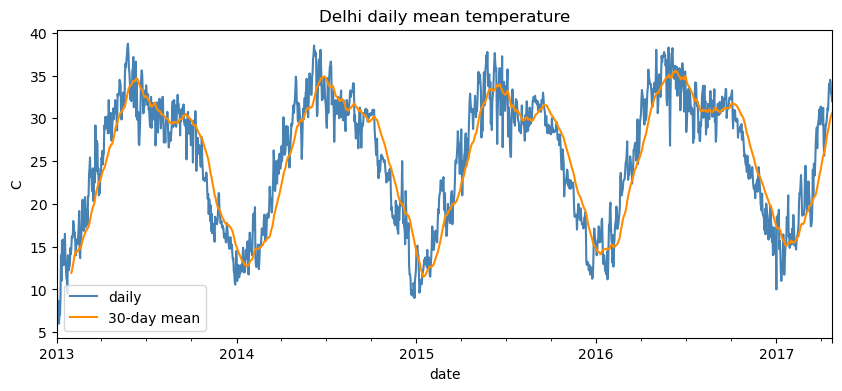

In [4]:
import matplotlib.pyplot as plt

df["meantemp"].plot(figsize=(10, 4), color="steelblue", label="daily")
df["meantemp"].rolling(30).mean().plot(color="darkorange", label="30-day mean")
plt.title("Delhi daily mean temperature")
plt.ylabel("C")
plt.legend()
plt.show()


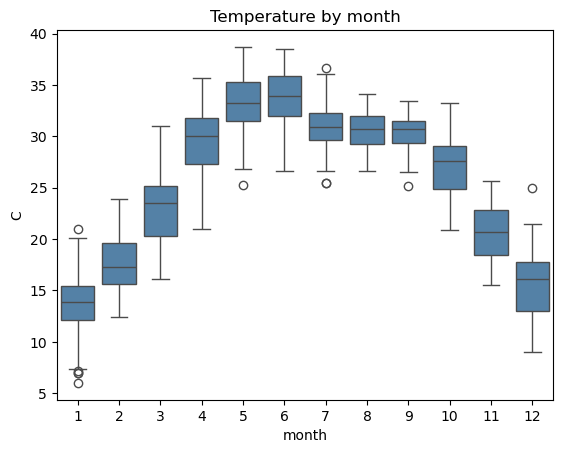

In [5]:
import seaborn as sns

sns.boxplot(x=df.index.month, y=df["meantemp"], color="steelblue")
plt.title("Temperature by month")
plt.xlabel("month")
plt.ylabel("C")
plt.show()


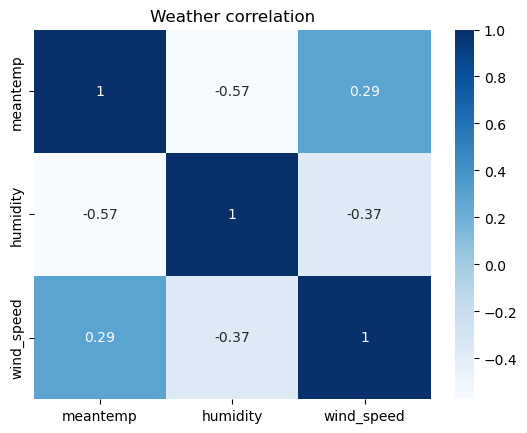

In [6]:
sns.heatmap(df[["meantemp", "humidity", "wind_speed"]].corr(), annot=True, cmap="Blues")
plt.title("Weather correlation")
plt.show()


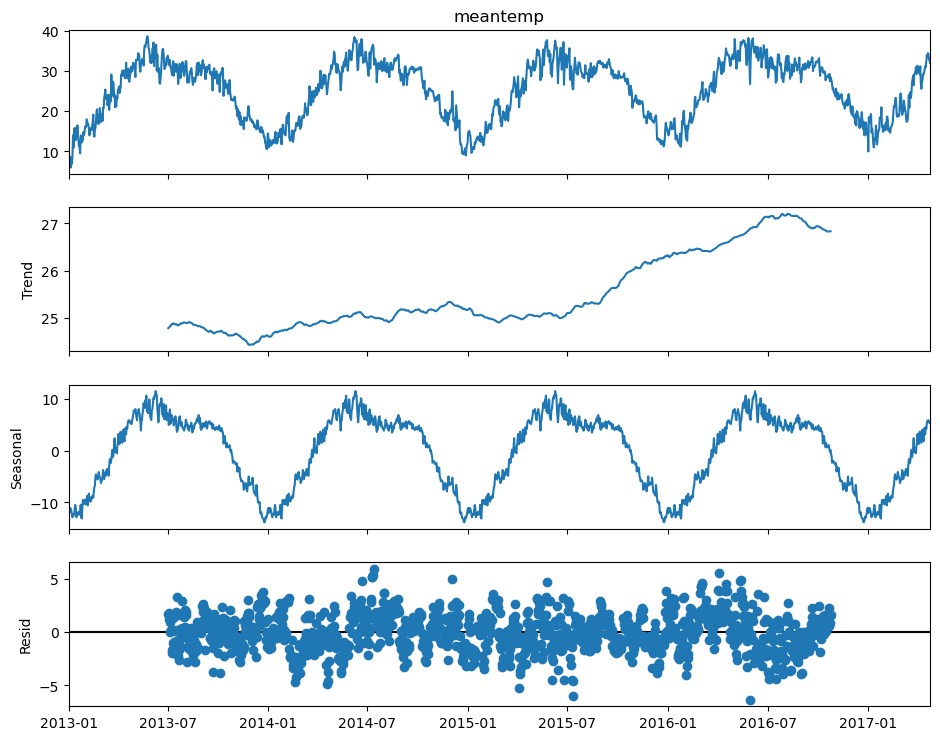

In [7]:
from statsmodels.tsa.seasonal import seasonal_decompose

result = seasonal_decompose(df["meantemp"], model="additive", period=365)
fig = result.plot()
fig.set_size_inches(10, 8)
plt.show()


In [8]:
import numpy as np
from numpy.lib.stride_tricks import sliding_window_view
from sklearn.preprocessing import MinMaxScaler

window = 14
raw = df[["meantemp", "humidity", "wind_speed"]].to_numpy()
split_raw = int(len(raw) * 0.8)
x_scaler = MinMaxScaler()
y_scaler = MinMaxScaler()
x_scaler.fit(raw[:split_raw])
y_scaler.fit(raw[:split_raw, :1])
scaled = x_scaler.transform(raw)
y_all = y_scaler.transform(raw[:, :1]).ravel()
x = np.moveaxis(sliding_window_view(scaled, window, axis=0)[:-1], 1, 2)
y = y_all[window:]
n_train = split_raw - window
x_train, x_test = x[:n_train], x[n_train:]
y_train, y_test = y[:n_train], y[n_train:]
print(x_train.shape, x_test.shape)


(1246, 14, 3) (315, 14, 3)


In [9]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

lin = LinearRegression()
lin.fit(x_train.reshape(len(x_train), -1), y_train)
lin_pred = lin.predict(x_test.reshape(len(x_test), -1))
print("Linear RMSE", np.sqrt(mean_squared_error(
    y_scaler.inverse_transform(y_test.reshape(-1, 1)),
    y_scaler.inverse_transform(lin_pred.reshape(-1, 1)),
)))


Linear RMSE 1.653605609137005


In [10]:
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(42)

dl = tf.keras.Sequential([
    layers.Input(shape=(window, 3)),
    layers.LSTM(32),
    layers.Dropout(0.2),
    layers.Dense(1),
])
dl.compile(optimizer="adam", loss="mse")
hist = dl.fit(
    x_train, y_train,
    validation_split=0.1,
    epochs=15,
    batch_size=32,
    callbacks=[EarlyStopping(patience=2, restore_best_weights=True)],
    verbose=1,
)
dl_pred = dl.predict(x_test, verbose=0).ravel()
print("LSTM RMSE", np.sqrt(mean_squared_error(
    y_scaler.inverse_transform(y_test.reshape(-1, 1)),
    y_scaler.inverse_transform(dl_pred.reshape(-1, 1)),
)))


Epoch 1/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.2732 - val_loss: 0.0156
Epoch 2/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0290 - val_loss: 0.0085
Epoch 3/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0145 - val_loss: 0.0049
Epoch 4/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0115 - val_loss: 0.0050
Epoch 5/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0117 - val_loss: 0.0050
LSTM RMSE 2.7635374037640306


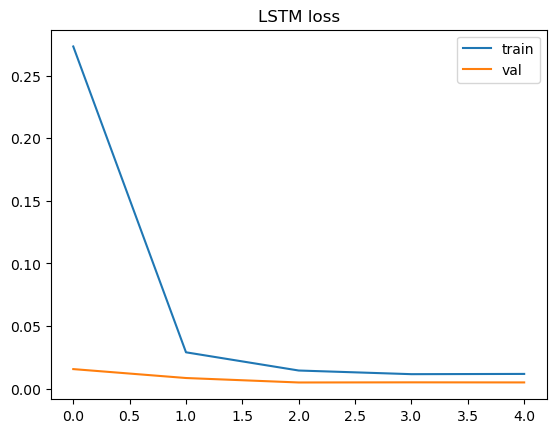

In [11]:
plt.plot(hist.history["loss"], label="train")
plt.plot(hist.history["val_loss"], label="val")
plt.title("LSTM loss")
plt.legend()
plt.show()


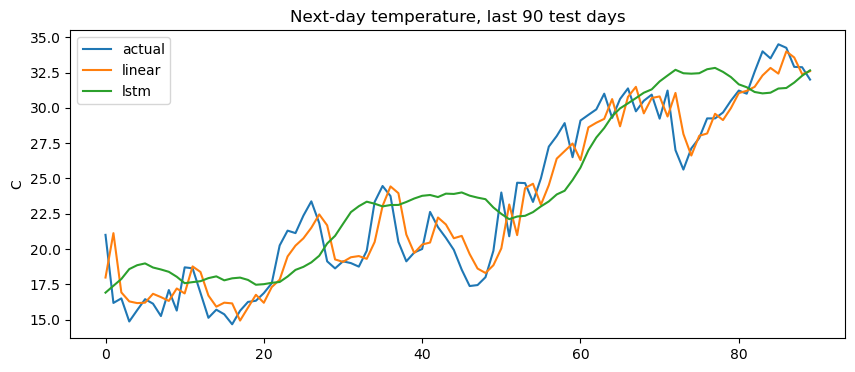

In [12]:
yt = y_scaler.inverse_transform(y_test.reshape(-1, 1)).ravel()
yp_lin = y_scaler.inverse_transform(lin_pred.reshape(-1, 1)).ravel()
yp_dl = y_scaler.inverse_transform(dl_pred.reshape(-1, 1)).ravel()
plt.figure(figsize=(10, 4))
plt.plot(yt[-90:], label="actual")
plt.plot(yp_lin[-90:], label="linear")
plt.plot(yp_dl[-90:], label="lstm")
plt.title("Next-day temperature, last 90 test days")
plt.ylabel("C")
plt.legend()
plt.show()


In [13]:
dl.save("delhi_temp_lstm.keras")


# Conclusion

I used the daily Delhi series from 2013 to 2017. The month boxplot and the seasonal decomposition show a yearly temperature cycle. Humidity and wind sit in the correlation heatmap because they move with temperature, so the window includes all three. The split is chronological, so the test days stay in the future. Linear regression on the last 14 days is the autoregressive baseline. The LSTM is the deep learning model: it reads 14 days of temperature, humidity and wind and predicts the next mean temperature. RMSE is in degrees. The LSTM is saved as delhi_temp_lstm.keras.
